# Sistema difuso Sugeno para clasificar Iris

**Desarrollo de los apartados A, B y C del examen.** Se implementa Sugeno de orden cero con dos entradas (`Petalwidth`, `Petallength`) y tres consecuentes constantes: Iris-setosa = 0, Iris-versicolor = 1 e Iris-virginica = 2.

El código de pertenencias, reglas, inferencia y confianza está en este notebook. No requiere archivos locales ni importa la implementación de los módulos del proyecto.


## 1. Descripción del problema

El sistema recibe ancho y largo del pétalo, determina cuánto se cumplen las condiciones de cinco reglas y combina sus consecuentes con un promedio ponderado. Se utiliza el operador mínimo para el AND de una regla y Sugeno de orden cero (consecuentes constantes).

Apartados:

- **A:** definición completa del sistema y su motor.
- **B:** evaluación de `Petalwidth=1.6`, `Petallength=5.0`.
- **C:** repetir esa entrada ponderando cada activación por la confiabilidad observada en la hoja correspondiente.


## 2. Variables y conjuntos difusos

Las entradas se miden en centímetros. Los nombres Small, Medium y Large describen conjuntos lingüísticos solapados. Se preservan los trapecios de la implementación anterior, coherentes con los límites del enunciado:

| Variable | Small | Medium | Large |
|---|---|---|---|
| Petalwidth | hasta 0.6 | hasta 1.5 | resto |
| Petallength | hasta 2.0 | hasta 4.9 | resto |

Los límites lingüísticos no son todos los cortes de las reglas: el árbol también usa `Petalwidth=1.7`. Se mantienen ambos valores en su función correspondiente.

## 3. Funciones de pertenencia

Un trapecio \((a,b,c,d)\) vale 0 fuera de \([a,d]\), sube linealmente de 0 a 1 entre \(a\) y \(b\), permanece en 1 entre \(b\) y \(c\), y baja linealmente a 0 entre \(c\) y \(d\). Si `c=d` se permite una rampa que llega a 1 en ese extremo. Los trapecios vecinos se solapan para permitir transiciones graduales.

Los parámetros son los del proyecto anterior; las líneas punteadas ubican los límites lingüísticos y los umbrales de árbol donde corresponden.

Ejemplo Petalwidth=1.6: {'Small': 0.0, 'Medium': 0.1999999999999993, 'Large': 0.8333333333333338}
Ejemplo Petallength=5.0: {'Small': 0.0, 'Medium': 0.24999999999999944, 'Large': 0.7500000000000006}


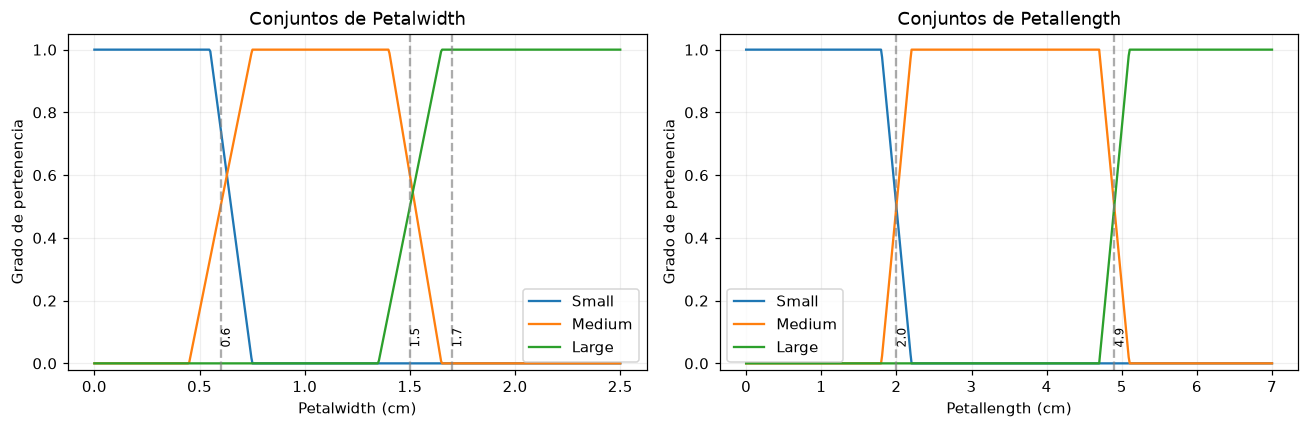

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def trapezoidal(x, a, b, c, d):
    """Función trapezoidal con hombros verticales permitidos (a=b o c=d)."""
    if not a <= b <= c <= d:
        raise ValueError('Se requiere a <= b <= c <= d.')
    if x < a or x > d:
        return 0.0
    if b <= x <= c:
        return 1.0
    if x < b:
        return 1.0 if a == b else (x-a)/(b-a)
    return 1.0 if c == d else (d-x)/(d-c)

# Parámetros (a,b,c,d) conservados de ConjuntosIris en sugeno/membresia.py.
CONJUNTOS = {
    'Petalwidth': {
        'Small': (-0.2, 0.0, 0.55, 0.75),
        'Medium': (0.45, 0.75, 1.4, 1.65),
        'Large': (1.35, 1.65, 3.0, 3.0),
    },
    'Petallength': {
        'Small': (-1.0, 0.0, 1.8, 2.2),
        'Medium': (1.8, 2.2, 4.7, 5.1),
        'Large': (4.7, 5.1, 8.0, 8.0),
    },
}

def grados_pertenencia(variable, valor):
    return {nombre: trapezoidal(valor, *parametros)
            for nombre, parametros in CONJUNTOS[variable].items()}

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for ax, variable, limite_x, cortes in [
    (ejes[0], 'Petalwidth', 2.5, [0.6, 1.5, 1.7]),
    (ejes[1], 'Petallength', 7.0, [2.0, 4.9]),
]:
    x = np.linspace(0, limite_x, 500)
    for etiqueta, parametros in CONJUNTOS[variable].items():
        y = [trapezoidal(v, *parametros) for v in x]
        ax.plot(x, y, label=etiqueta)
    for corte in cortes:
        ax.axvline(corte, linestyle='--', color='gray', alpha=.65)
        ax.text(corte, .06, str(corte), rotation=90, fontsize=8)
    ax.set(title=f'Conjuntos de {variable}', xlabel=f'{variable} (cm)',
           ylabel='Grado de pertenencia', ylim=(-.02, 1.05))
    ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

print('Ejemplo Petalwidth=1.6:', grados_pertenencia('Petalwidth', 1.6))
print('Ejemplo Petallength=5.0:', grados_pertenencia('Petallength', 5.0))

Los grados del ejemplo muestran el solapamiento: PW=1.6 pertenece parcialmente a Medium y Large; PL=5.0 pertenece parcialmente a Medium y Large. Un grado de pertenencia expresa compatibilidad con un conjunto, no probabilidad.

## 4. Construcción de las reglas

Se conserva la estructura del árbol y los consecuentes constantes del enunciado. La condición `PW > 0.6` que precede a R2 se incluye explícitamente, aunque `PW > 1.7` ya la implique en lógica clásica.

In [2]:
CLASE = {'Iris-setosa': 0.0, 'Iris-versicolor': 1.0, 'Iris-virginica': 2.0}
REGLAS = [
    {'id':'R1', 'condicion':'PW <= 0.6', 'consecuente':CLASE['Iris-setosa'], 'clase':'Iris-setosa'},
    {'id':'R2', 'condicion':'PW > 0.6 AND PW > 1.7', 'consecuente':CLASE['Iris-virginica'], 'clase':'Iris-virginica'},
    {'id':'R3', 'condicion':'PW > 0.6 AND PW <= 1.7 AND PL <= 4.9', 'consecuente':CLASE['Iris-versicolor'], 'clase':'Iris-versicolor'},
    {'id':'R4', 'condicion':'PW > 0.6 AND PW <= 1.7 AND PL > 4.9 AND PW <= 1.5', 'consecuente':CLASE['Iris-virginica'], 'clase':'Iris-virginica'},
    {'id':'R5', 'condicion':'PW > 0.6 AND PW <= 1.7 AND PL > 4.9 AND PW > 1.5', 'consecuente':CLASE['Iris-versicolor'], 'clase':'Iris-versicolor'},
]
for regla in REGLAS:
    print(f"{regla['id']}: SI {regla['condicion']} ENTONCES {regla['clase']} (z={regla['consecuente']:.0f})")

R1: SI PW <= 0.6 ENTONCES Iris-setosa (z=0)
R2: SI PW > 0.6 AND PW > 1.7 ENTONCES Iris-virginica (z=2)
R3: SI PW > 0.6 AND PW <= 1.7 AND PL <= 4.9 ENTONCES Iris-versicolor (z=1)
R4: SI PW > 0.6 AND PW <= 1.7 AND PL > 4.9 AND PW <= 1.5 ENTONCES Iris-virginica (z=2)
R5: SI PW > 0.6 AND PW <= 1.7 AND PL > 4.9 AND PW > 1.5 ENTONCES Iris-versicolor (z=1)


Para combinar condiciones AND usamos el mínimo de sus grados. Cada regla produce una fuerza de activación `w` entre 0 y 1 y un consecuente constante `z` asociado con su clase.

## 5. Fuzzificación y activación de reglas

Las transiciones de los umbrales del árbol usan las rampas de 0.2 cm definidas en la solución previa. Para un corte `t`, `μ>t` crece linealmente entre `t−0.1` y `t+0.1`; `μ≤t = 1−μ>t`. Se evalúan las condiciones y el mínimo calcula el AND. Esto suaviza los cortes sin cambiar los umbrales nominales del árbol.

In [3]:
def rampa_mayor_que(x, limite, ancho=0.2):
    inicio, fin = limite-ancho/2, limite+ancho/2
    if x <= inicio + 1e-12: return 0.0
    if x >= fin - 1e-12: return 1.0
    return (x-inicio)/ancho

def rampa_menor_igual(x, limite, ancho=0.2):
    return 1.0-rampa_mayor_que(x, limite, ancho)

def fuzzificar(pw, pl):
    return {
        'Petalwidth': grados_pertenencia('Petalwidth', pw),
        'Petallength': grados_pertenencia('Petallength', pl),
    }

def activar_reglas(pw, pl):
    pw_mayor_06 = rampa_mayor_que(pw, 0.6)
    pw_menor_igual_06 = 1.0-pw_mayor_06
    pw_mayor_17 = rampa_mayor_que(pw, 1.7)
    pw_menor_igual_17 = 1.0-pw_mayor_17
    pl_menor_igual_49 = rampa_menor_igual(pl, 4.9)
    pl_mayor_49 = 1.0-pl_menor_igual_49
    pw_menor_igual_15 = rampa_menor_igual(pw, 1.5)
    pw_mayor_15 = 1.0-pw_menor_igual_15

    return {
        'R1': pw_menor_igual_06,
        'R2': min(pw_mayor_06, pw_mayor_17),
        'R3': min(pw_mayor_06, pw_menor_igual_17, pl_menor_igual_49),
        'R4': min(pw_mayor_06, pw_menor_igual_17, pl_mayor_49, pw_menor_igual_15),
        'R5': min(pw_mayor_06, pw_menor_igual_17, pl_mayor_49, pw_mayor_15),
    }

print('Transiciones de ejemplo:')
for limite in (0.6, 1.5, 1.7, 4.9):
    valor = 1.6 if limite in (0.6, 1.5, 1.7) else 5.0
    print(f'  en el corte {limite}: μ> = {rampa_mayor_que(valor, limite):.3f}; μ<= = {rampa_menor_igual(valor, limite):.3f}')

Transiciones de ejemplo:
  en el corte 0.6: μ> = 1.000; μ<= = 0.000
  en el corte 1.5: μ> = 1.000; μ<= = 0.000
  en el corte 1.7: μ> = 0.000; μ<= = 1.000
  en el corte 4.9: μ> = 1.000; μ<= = 0.000


La fuzzificación lingüística y la activación de reglas son cálculos relacionados pero distintos: la primera evalúa Small/Medium/Large con trapecios; la segunda evalúa las condiciones del árbol con rampas. El mínimo representa el cumplimiento conjunto de los antecedentes.

## 6. Motor Sugeno de orden cero

Para activaciones `wᵢ` y consecuentes `zᵢ`, la salida es `y = Σ(wᵢ zᵢ) / Σ(wᵢ)`. El denominador normaliza las contribuciones. Si todas las activaciones son cero, se devuelve `None` y no se asigna clase. Para convertir la salida a clase se usa el entero más cercano en el rango 0..2: clase 0 si `y <= 0.5`, clase 1 si `0.5 < y <= 1.5` y clase 2 si `y > 1.5`; se recorta a 0..2. En un empate exacto entre dos clases se elige el índice menor.

In [4]:
def clase_desde_salida(salida):
    """Clase numérica más cercana; empates se resuelven hacia el índice menor."""
    if salida is None:
        return None
    indice = max(0, min(2, int(salida + 0.5 - 1e-12)))
    return indice

def evaluar_sugeno(pw, pl, confianzas=None):
    grados = fuzzificar(pw, pl)
    activaciones = activar_reglas(pw, pl)
    consecuentes = {regla['id']: regla['consecuente'] for regla in REGLAS}
    if confianzas is None:
        pesos = activaciones.copy()
    else:
        pesos = {regla: activaciones[regla]*confianzas[regla] for regla in activaciones}
    productos = {regla: pesos[regla]*consecuentes[regla] for regla in pesos}
    numerador = sum(productos.values())
    denominador = sum(pesos.values())
    salida = None if denominador == 0 else numerador/denominador
    return {
        'grados':grados, 'activaciones':activaciones, 'pesos':pesos,
        'consecuentes':consecuentes, 'productos':productos,
        'numerador':numerador, 'denominador':denominador,
        'salida':salida, 'clase':clase_desde_salida(salida),
    }

print('Prueba del denominador cero:',
      'sin salida' if sum({'R1':0.0}.values()) == 0 else 'hay salida')

Prueba del denominador cero: sin salida


La función devuelve los valores intermedios además de la clase, de modo que cada apartado puede mostrar cómo se obtuvo la respuesta.

## 7. Apartado A — sistema Sugeno completo

El sistema ya está definido: entradas PW y PL, tres conjuntos trapezoidales por entrada, las reglas R1–R5 con operador mínimo, consecuentes constantes 0/1/2 y salida mediante promedio ponderado. La conversión es a la clase numérica más cercana; los empates van al índice menor. Los conjuntos Small/Medium/Large usan sus límites lingüísticos y las reglas conservan sus umbrales de árbol, incluido PW=1.7.

In [5]:
print('Entradas: Petalwidth y Petallength (cm)')
print('Consecuentes: 0=Iris-setosa, 1=Iris-versicolor, 2=Iris-virginica')
print('Operador AND: mínimo; inferencia: suma(w*z) / suma(w)')
print('Política de clase: vecino entero más cercano; empate al índice menor.')

Entradas: Petalwidth y Petallength (cm)
Consecuentes: 0=Iris-setosa, 1=Iris-versicolor, 2=Iris-virginica
Operador AND: mínimo; inferencia: suma(w*z) / suma(w)
Política de clase: vecino entero más cercano; empate al índice menor.


## 8. Apartado B — entrada PW=1.6, PL=5.0

Se ejecuta el motor definido arriba y se presentan grados lingüísticos, activaciones, consecuentes, productos y las dos sumas del promedio. La clase se deriva de la salida calculada.

In [6]:
PW, PL = 1.6, 5.0
resultado_B = evaluar_sugeno(PW, PL)

print('1. Fuzzificación (trapecios):')
for variable, grados in resultado_B['grados'].items():
    print(f'  {variable}: ' + ', '.join(f'{nombre}={valor:.6f}' for nombre,valor in grados.items()))

print('\n2–4. Activación, consecuente y producto:')
print(f"{'Regla':<7}{'w':>12}{'z':>12}{'w*z':>14}")
for regla in REGLAS:
    rid=regla['id']
    print(f"{rid:<7}{resultado_B['activaciones'][rid]:>12.6f}{resultado_B['consecuentes'][rid]:>12.2f}{resultado_B['productos'][rid]:>14.6f}")

print(f"\n5. Numerador = Σ(w*z) = {resultado_B['numerador']:.6f}")
print(f"   Denominador = Σ(w) = {resultado_B['denominador']:.6f}")
print(f"6. Salida Sugeno = {resultado_B['numerador']:.6f} / {resultado_B['denominador']:.6f} = {resultado_B['salida']:.6f}")
print(f"7. Clase = {resultado_B['clase']} ({['Iris-setosa','Iris-versicolor','Iris-virginica'][resultado_B['clase']]})")
assert resultado_B['clase'] == 1
assert resultado_B['activaciones'] == {'R1':0.0,'R2':0.0,'R3':0.0,'R4':0.0,'R5':1.0}
assert resultado_B['numerador'] == resultado_B['denominador'] == resultado_B['salida'] == 1.0

1. Fuzzificación (trapecios):
  Petalwidth: Small=0.000000, Medium=0.200000, Large=0.833333
  Petallength: Small=0.000000, Medium=0.250000, Large=0.750000

2–4. Activación, consecuente y producto:
Regla             w           z           w*z
R1         0.000000        0.00      0.000000
R2         0.000000        2.00      0.000000
R3         0.000000        1.00      0.000000
R4         0.000000        2.00      0.000000
R5         1.000000        1.00      1.000000

5. Numerador = Σ(w*z) = 1.000000
   Denominador = Σ(w) = 1.000000
6. Salida Sugeno = 1.000000 / 1.000000 = 1.000000
7. Clase = 1 (Iris-versicolor)


## 9. Incorporación de incertidumbre

La confiabilidad de una regla se estima con los ejemplos de su hoja: `confianza = bien / (bien + mal)`. Para el apartado C, se multiplica la activación por esa confiabilidad y se vuelve a calcular el promedio Sugeno. Estos valores resumen los aciertos de las hojas proporcionados por el examen.

In [7]:
DATOS_HOJAS = {
    'R1': (50, 0),
    'R2': (46, 1),
    'R3': (48, 1),
    'R4': (3, 0),
    'R5': (3, 1),
}
CONFIANZAS = {
    regla: bien/(bien+mal)
    for regla,(bien,mal) in DATOS_HOJAS.items()
}
print(f"{'Regla':<7}{'Bien':>8}{'Mal':>8}{'Confianza':>15}")
for regla,(bien,mal) in DATOS_HOJAS.items():
    print(f'{regla:<7}{bien:>8}{mal:>8}{CONFIANZAS[regla]:>14.6%}')

Regla      Bien     Mal      Confianza
R1           50       0   100.000000%
R2           46       1    97.872340%
R3           48       1    97.959184%
R4            3       0   100.000000%
R5            3       1    75.000000%


## 10. Apartado C — volver a evaluar PW=1.6, PL=5.0

Se repite exactamente la entrada del apartado B, esta vez con `wᵢ′ = wᵢ × confianzaᵢ`. Los consecuentes permanecen iguales; se actualizan los pesos y los productos antes de normalizar.

In [8]:
resultado_C = evaluar_sugeno(PW, PL, confianzas=CONFIANZAS)
print(f"{'Regla':<7}{'w':>12}{'confianza':>14}{'w ajustada':>14}{'z':>10}{'w*z':>14}")
for regla in REGLAS:
    rid=regla['id']
    print(f"{rid:<7}{resultado_C['activaciones'][rid]:>12.6f}{CONFIANZAS[rid]:>14.6f}{resultado_C['pesos'][rid]:>14.6f}{resultado_C['consecuentes'][rid]:>10.2f}{resultado_C['productos'][rid]:>14.6f}")
print(f"\nNumerador ajustado = {resultado_C['numerador']:.6f}")
print(f"Denominador ajustado = {resultado_C['denominador']:.6f}")
print(f"Salida Sugeno ajustada = {resultado_C['salida']:.6f}")
print(f"Clase final = {resultado_C['clase']} ({['Iris-setosa','Iris-versicolor','Iris-virginica'][resultado_C['clase']]})")
print('¿Cambió la clase respecto al apartado B?', resultado_C['clase'] != resultado_B['clase'])
assert resultado_C['clase'] == 1
assert resultado_C['pesos']['R5'] == 0.75
assert resultado_C['numerador'] == resultado_C['denominador'] == 0.75
assert resultado_C['salida'] == 1.0 and resultado_C['clase'] == resultado_B['clase']

Regla             w     confianza    w ajustada         z           w*z
R1         0.000000      1.000000      0.000000      0.00      0.000000
R2         0.000000      0.978723      0.000000      2.00      0.000000
R3         0.000000      0.979592      0.000000      1.00      0.000000
R4         0.000000      1.000000      0.000000      2.00      0.000000
R5         1.000000      0.750000      0.750000      1.00      0.750000

Numerador ajustado = 0.750000
Denominador ajustado = 0.750000
Salida Sugeno ajustada = 1.000000
Clase final = 1 (Iris-versicolor)
¿Cambió la clase respecto al apartado B? False


En esta entrada solo R5 tiene activación positiva. La confianza de R5 es 0.75, así que numerador y denominador se multiplican ambos por 0.75; su cociente sigue siendo 1.0. Por eso la clase no cambia entre B y C. Si varias reglas con consecuentes distintos estuvieran activas, reducir el peso relativo de una regla sí podría cambiar la salida.

## 11. Conclusión

Se resolvieron A, B y C con el mismo motor visible en el notebook. El sistema combina activaciones de reglas y consecuentes constantes mediante una media ponderada y transforma la salida continua a la clase más cercana. Se conservaron los límites lingüísticos, los umbrales del árbol, los consecuentes y los conteos de confiabilidad del enunciado.